# 💎 Diamond Price Prediction — a Jeweler's Take on Machine Learning

Predict the price of a diamond from the "4 Cs" (carat, cut, color, clarity) and its physical dimensions, using 53,940 diamonds.

I work in my family's gold and jewelry shop in Kadhimiya, Baghdad, so this project combines **domain expertise with data**: several cleaning decisions below come from knowing what a real diamond can and cannot look like.

**Author:** Reda Akram · Computer Science (AI), University of Technology – Baghdad

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, StackingRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
sns.set_theme(style="whitegrid"); RANDOM_STATE = 42

## 1. Data dictionary

| Column | Meaning |
|---|---|
| carat | Weight (1 ct = 0.2 g) — the main price driver |
| cut | Fair < Good < Very Good < Premium < Ideal |
| color | J (worst) → D (best, colorless) |
| clarity | I1 (worst) < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF (best) |
| depth, table | Proportions (%) |
| x, y, z | Length, width, depth in mm |
| price | Price in USD (target) |

In [2]:
df = pd.read_csv("data/diamonds.csv").drop(columns=["Unnamed: 0"], errors="ignore")
print(df.shape); df.describe().round(2)

(53940, 10)


,carat,depth,table,price,x,y,z
count,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00,53940.00
mean,0.80,61.75,57.46,3932.80,5.73,5.73,3.54
std,0.47,1.43,2.23,3989.44,1.12,1.14,0.71
min,0.20,43.00,43.00,326.00,0.00,0.00,0.00
25%,0.40,61.00,56.00,950.00,4.71,4.72,2.91
50%,0.70,61.80,57.00,2401.00,5.70,5.71,3.53
75%,1.04,62.50,59.00,5324.25,6.54,6.54,4.04
max,5.01,79.00,95.00,18823.00,10.74,58.90,31.80


## 2. EDA — what really sets the price?

/tmp/ipykernel_403/2386699652.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="cut", y="price", order=["Fair","Good","Very Good","Premium","Ideal"], ax=axes[1], palette="Blues")


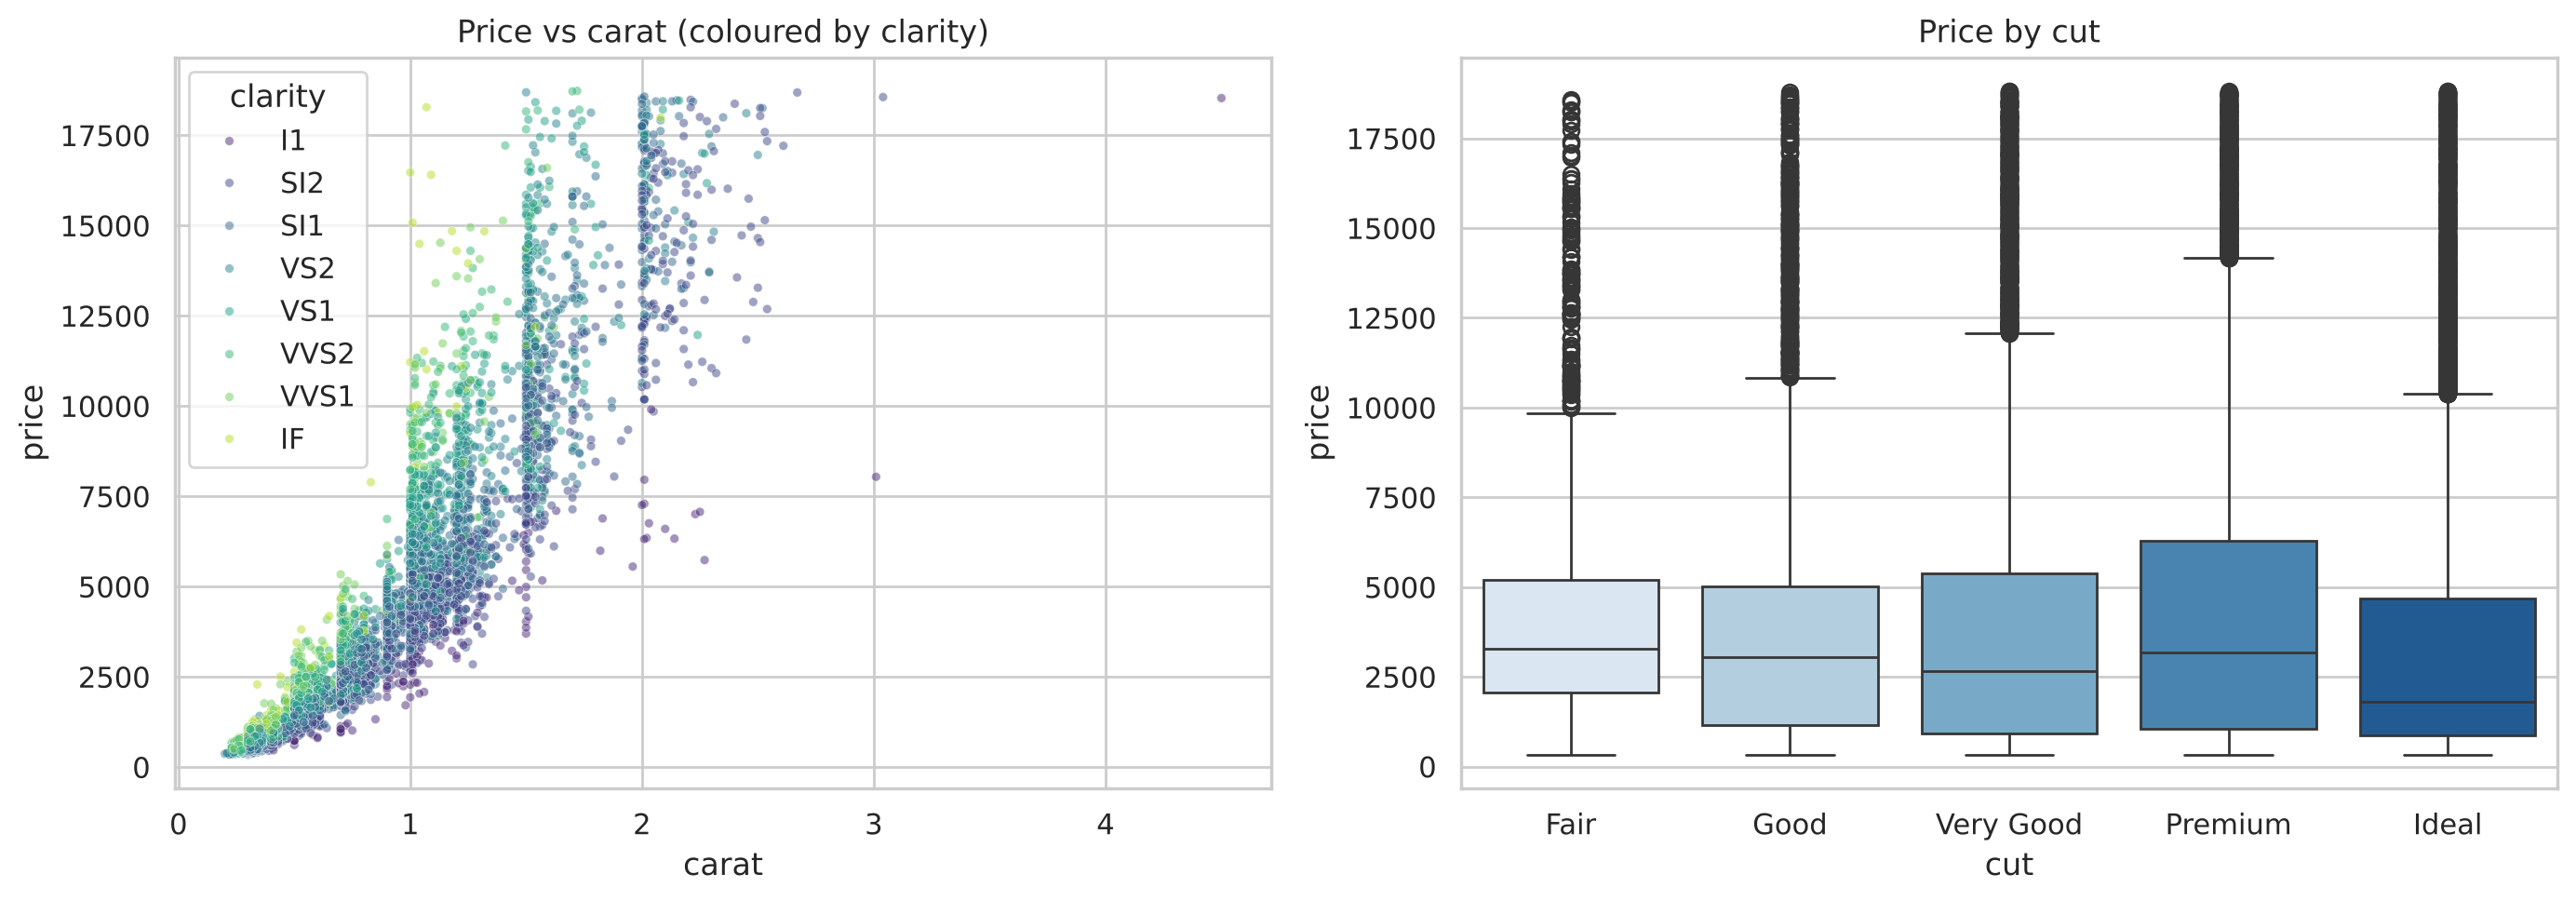

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=df.sample(8000, random_state=1), x="carat", y="price", hue="clarity", alpha=0.5, s=12, ax=axes[0],
                hue_order=["I1","SI2","SI1","VS2","VS1","VVS2","VVS1","IF"], palette="viridis")
axes[0].set_title("Price vs carat (coloured by clarity)")
sns.boxplot(data=df, x="cut", y="price", order=["Fair","Good","Very Good","Premium","Ideal"], ax=axes[1], palette="Blues")
axes[1].set_title("Price by cut")
plt.tight_layout(); plt.savefig("images/eda_price.png", dpi=120, bbox_inches="tight"); plt.show()

In [4]:
df.groupby("cut", observed=True)[["carat", "price"]].mean().loc[["Fair","Good","Very Good","Premium","Ideal"]].round(2)

,carat,price
cut,,
Fair,1.05,4358.76
Good,0.85,3928.86
Very Good,0.81,3981.76
Premium,0.89,4584.26
Ideal,0.70,3457.54


**Insights**
* **Weight dominates.** Price rises non-linearly with carat, and the jump is especially sharp above ~1.5 ct.
* **The "Fair cut paradox."** Fair-cut diamonds have a *higher* average price than Ideal ones. Not because a bad cut is valuable — Fair stones in this dataset are much **heavier** on average, and the weight hides the poor cut.
* **Clarity alone doesn't decide price.** Large stones with poor clarity (I1, SI2) can still be very expensive. Every feature has to be read *together with carat*.

## 3. Data quality — a jeweler's sanity check

Plotting the dimensions shows values like a **width of 58.9 mm** or a **depth of 31.8 mm**. A diamond that wide would weigh hundreds of carats — it doesn't exist on the market. Other rows have a dimension of **0 mm**, which is physically impossible.

Instead of "fixing" them with guesses (e.g. dividing by 10), we measure how many there are first.

In [5]:
zero_dims = (df[["x","y","z"]] == 0).any(axis=1)
impossible = (df["y"] > 20) | (df["z"] > 20) | (df["z"] < 1)
print("Rows with a 0 mm dimension :", zero_dims.sum())
print("Rows with impossible sizes :", (impossible & ~zero_dims).sum())
df[impossible | zero_dims].head(8)

Rows with a 0 mm dimension : 20
Rows with impossible sizes : 3


,carat,cut,color,clarity,depth,table,price,x,y,z
2207,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0


Only a few dozen rows out of ~54,000 (< 0.1%) are corrupted, so removing them is the honest choice — it costs nothing and avoids feeding the model physically impossible stones.

In [6]:
clean = df[~(zero_dims | impossible)].copy()
print("Rows kept:", len(clean), "| removed:", len(df) - len(clean))

Rows kept: 53917 | removed: 23


## 4. Modelling

In [7]:
X = clean.drop(columns="price"); y = clean["price"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
num = ["carat", "depth", "table", "x", "y", "z"]; cat = ["cut", "color", "clarity"]
prep = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def evaluate(name, model):
    model.fit(X_train, y_train); p = model.predict(X_test)
    return {"model": name, "R²": r2_score(y_test, p), "RMSE ($)": root_mean_squared_error(y_test, p),
            "MAE ($)": mean_absolute_error(y_test, p), "MAPE (%)": 100 * mean_absolute_percentage_error(y_test, p)}, p

results = []
for name, m in [("Linear Regression", LinearRegression()),
                ("Random Forest", RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)),
                ("Gradient Boosting", HistGradientBoostingRegressor(max_iter=500, learning_rate=0.1, random_state=RANDOM_STATE))]:
    r, _ = evaluate(name, Pipeline([("prep", prep), ("model", m)])); results.append(r)
pd.DataFrame(results).round(3)

,model,R²,RMSE ($),MAE ($),MAPE (%)
0,Linear Regression,0.925,1090.259,716.529,37.936
1,Random Forest,0.976,609.343,288.480,6.983
2,Gradient Boosting,0.982,535.382,280.506,7.889


### Final model: Stacking ensemble

Three very different learners each see the data their own way — **Random Forest** (trees), **KNN** (similar stones) and **SVR** (kernel) — and a Linear Regression meta-model learns how much to trust each one.

In [8]:
stack = StackingRegressor(
    estimators=[("rf", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE)),
                ("knn", KNeighborsRegressor(n_neighbors=5)),
                ("svr", SVR())],
    final_estimator=LinearRegression(), cv=5, n_jobs=-1)
r, y_pred = evaluate("Stacking (RF + KNN + SVR)", Pipeline([("prep", prep), ("model", stack)]))
results.append(r)
table = pd.DataFrame(results).round(3); table

,model,R²,RMSE ($),MAE ($),MAPE (%)
0,Linear Regression,0.925,1090.259,716.529,37.936
1,Random Forest,0.976,609.343,288.480,6.983
2,Gradient Boosting,0.982,535.382,280.506,7.889
3,Stacking (RF + KNN + SVR),0.977,603.091,288.342,7.015


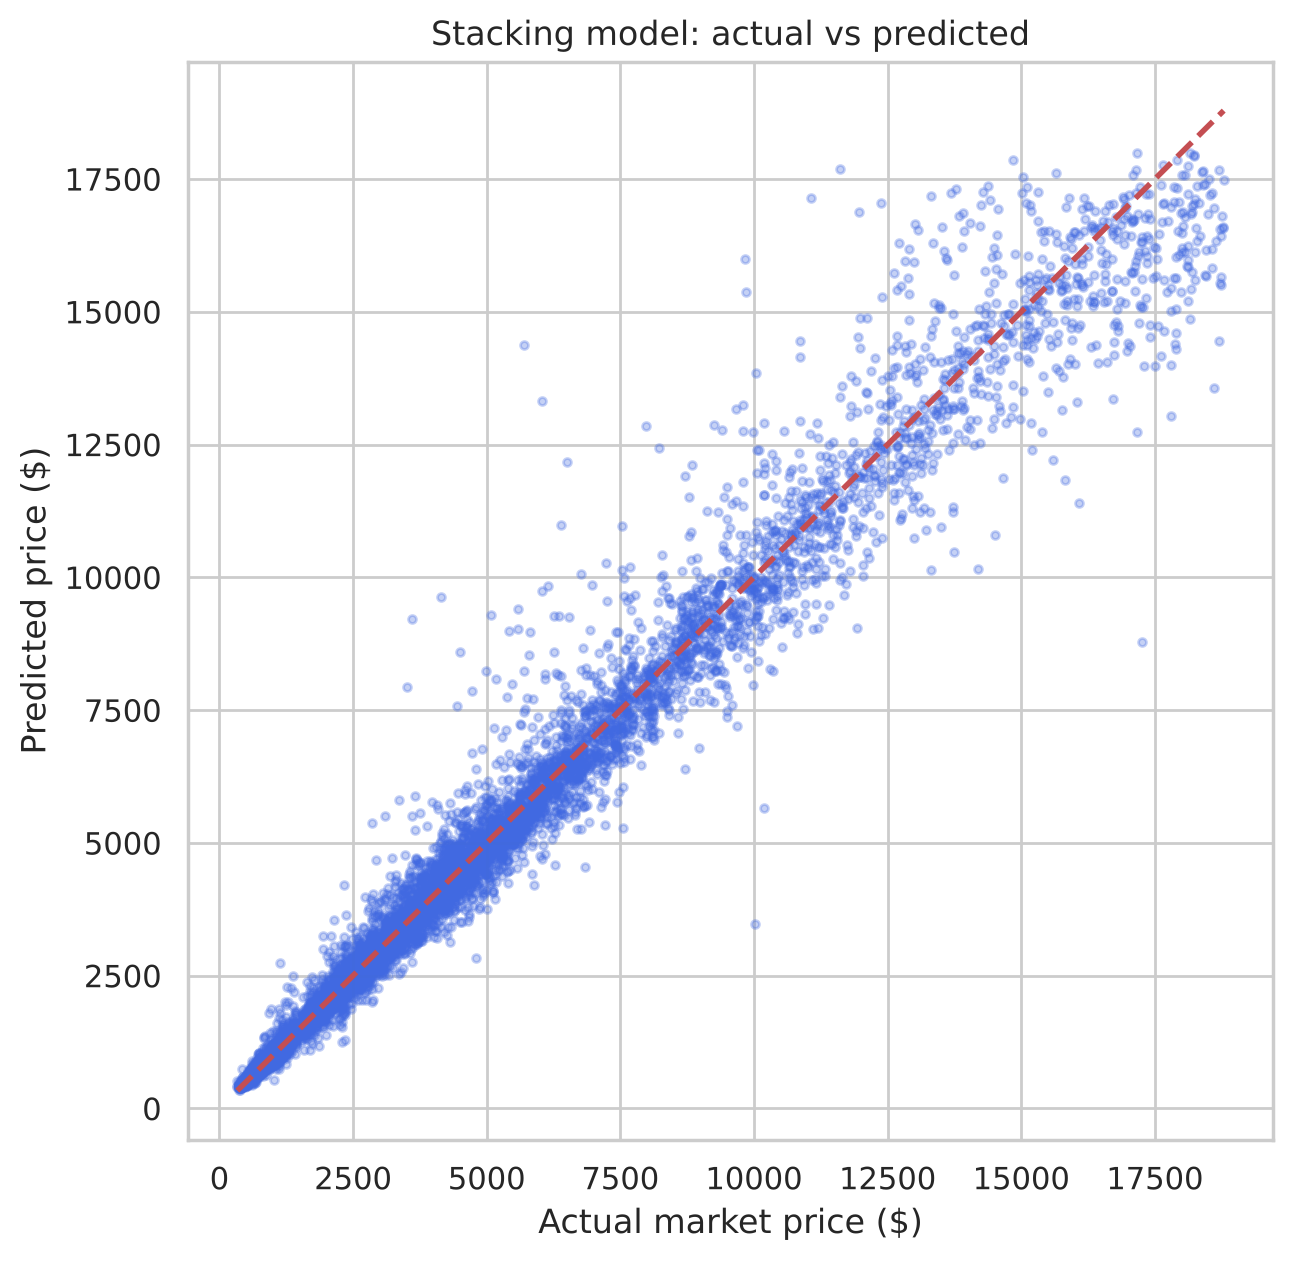

In [9]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.3, s=8, color="royalblue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--", lw=2)
plt.xlabel("Actual market price ($)"); plt.ylabel("Predicted price ($)"); plt.title("Stacking model: actual vs predicted")
plt.savefig("images/actual_vs_predicted.png", dpi=120, bbox_inches="tight"); plt.show()

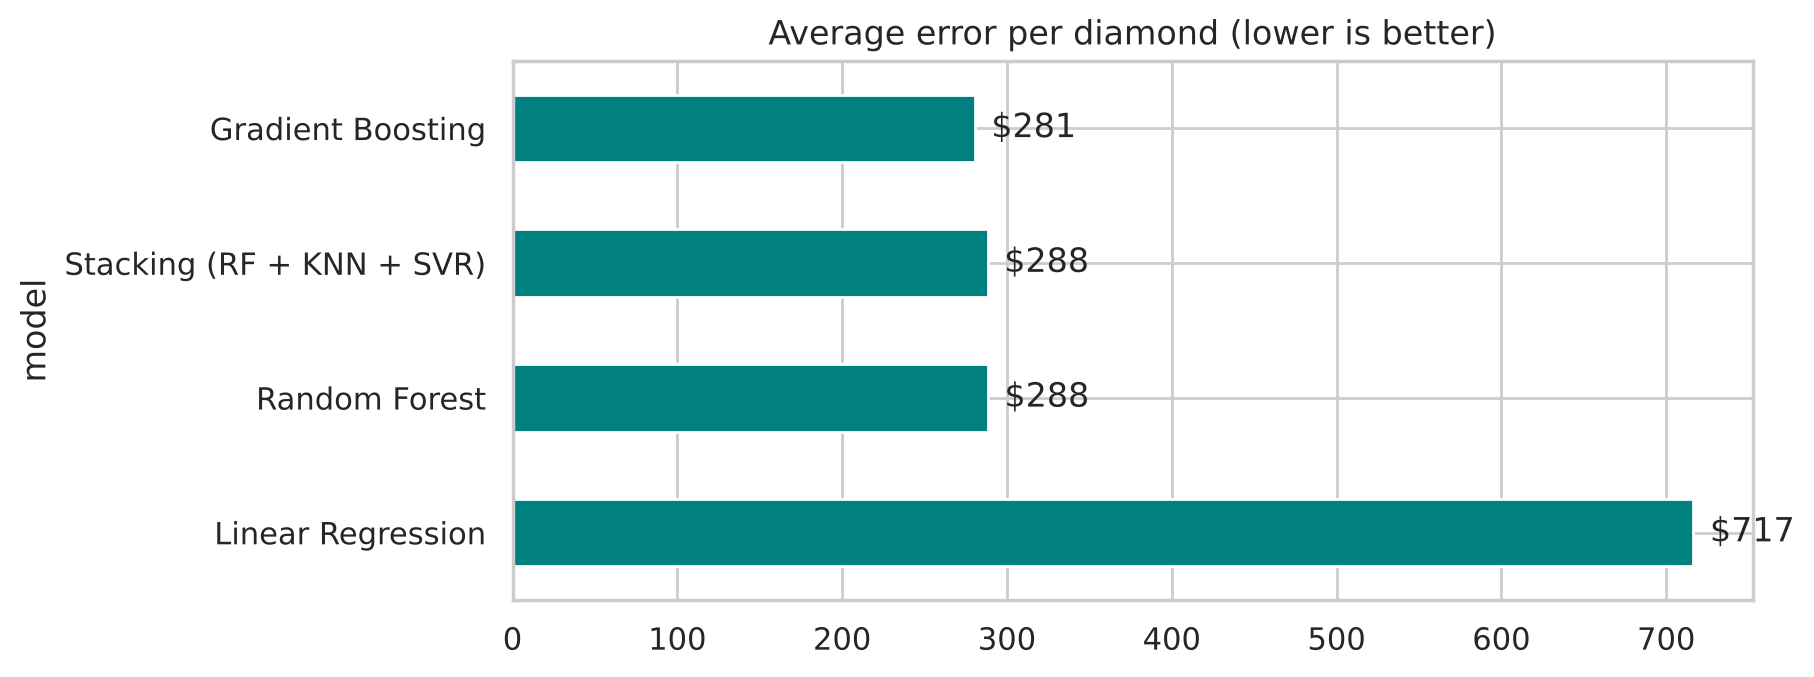

In [10]:
t = table.set_index("model")["MAE ($)"].sort_values(ascending=False)
t.plot(kind="barh", figsize=(8, 3.5), color="teal")
for i, v in enumerate(t): plt.text(v + 10, i, f"${v:,.0f}", va="center")
plt.title("Average error per diamond (lower is better)"); plt.savefig("images/model_comparison.png", dpi=120, bbox_inches="tight"); plt.show()

## 5. Conclusion

* The ensemble models explain about **98% of the price variance**, with an average error of under **$300** per stone and a typical error of **~7%** of the price.
* The **Stacking ensemble** (R² 0.977, MAE $288) and **Gradient Boosting** (R² 0.982, MAE $281) perform almost identically; Gradient Boosting is slightly better and far faster to train, so it is the practical choice for deployment.
* A plain linear model is far worse (MAPE ~38%) — diamond pricing is strongly non-linear in weight.
* Domain knowledge mattered: the impossible-dimension rows would never have been caught by looking at accuracy numbers alone.

**Next steps:** predict `log(price)` to reduce the percentage error on cheap stones, and wrap the model in a small web app that jewelers can use to sanity-check quotes.